# manasight 05b: a small neural network on the CLIP features

**Question:** do the frozen CLIP features hold more than a single layer can read out?

The linear probe in notebook 05 reached 44.6% on color. Its training accuracy (49%) was close to its validation
accuracy (47%): it was not memorizing, it had run out of capacity. A single layer can only add features up.
A network with a **hidden layer** can also combine them.

```
picture -> CLIP (frozen) -> 512 numbers -> hidden layer -> 7 classes
                                           \_______ trained here _______/
```

CLIP is still frozen and its features are still the saved ones, so this trains in minutes on a CPU.

- If the network clearly beats the probe: the features hold more, and a bigger head is a cheap win.
- If it does not: the frozen features are used up, and the only way further is to train CLIP itself (next step).

Sections:
1. Load data and features
2. The model and the training setup
3. Train, and choose the size of the hidden layer
4. Test results for color
5. Type
6. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.clip import load_image_features
from manasight.model import SmallNetwork, predict_probabilities, count_weights
from manasight.engine import train
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72
device = torch.device("cpu")

## 1. Load data and features

Same saved CLIP features and the same standardization as in notebook 05.

In [2]:
all_cards = load_cards()
cards = all_cards[~all_cards.is_junk].reset_index(drop=True)
features = load_image_features(cards)

is_train = (cards.split == "train").to_numpy()
is_val = (cards.split == "val").to_numpy()
is_test = (cards.split == "test").to_numpy()

scaler = StandardScaler().fit(features[is_train])
x = scaler.transform(features).astype(np.float32)
print("features:", x.shape, x.dtype)
print(f"train {is_train.sum():,}   val {is_val.sum():,}   test {is_test.sum():,}")

features: (47203, 512) float32
train 35,383   val 4,798   test 3,392


## 2. The model and the training setup

**Model** (`SmallNetwork` in `src/manasight/model.py`): 512 inputs -> hidden layer with ReLU -> dropout -> 7 outputs.

**Training choices, and why:**
- **Loss: cross-entropy.** The standard loss for "exactly one of several classes".
- **Optimizer: Adam,** learning rate 0.001, with a little weight decay (0.0001) to hold the weights back.
- **Dropout 0.5.** There are far more weights here than in the probe, so the network could memorize the training
  cards. Dropout makes that harder.
- **DataLoader,** batches of 256, training data shuffled every epoch.
- **Learning-rate schedule:** halve the learning rate when the validation loss stops improving for 2 epochs.
- **Early stopping:** stop when the validation loss has not improved for 6 epochs, and keep the best weights.

The training loop itself (`src/manasight/engine.py`) is the plain PyTorch loop: forward pass, loss, backward pass,
optimizer step.

In [3]:
def make_loaders(labels, classes):
    # class names -> numbers 0..6, then DataLoaders for train and val
    class_number = {name: i for i, name in enumerate(classes)}
    y = np.array([class_number[name] for name in labels])
    train_data = TensorDataset(torch.from_numpy(x[is_train]), torch.from_numpy(y[is_train]))
    val_data = TensorDataset(torch.from_numpy(x[is_val]), torch.from_numpy(y[is_val]))
    train_loader = DataLoader(train_data, batch_size=256, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=256, shuffle=False)
    return train_loader, val_loader


def train_network(train_loader, val_loader, hidden, classes, verbose):
    torch.manual_seed(0)   # same starting weights every run
    model = SmallNetwork(inputs=x.shape[1], hidden=hidden, classes=len(classes), dropout=0.5)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    history = train(model, train_loader, val_loader, optimizer, loss_fn, epochs=60, device=device,
                    scheduler=scheduler, patience=6, verbose=verbose)
    return model, history


color_train_loader, color_val_loader = make_loaders(cards.color, COLOR_CLASSES)
example_model = SmallNetwork(inputs=512, hidden=256, classes=7)
print(example_model)
print(f"weights to train: {count_weights(example_model):,}   (the linear probe had {512 * 7 + 7:,})")

SmallNetwork(
  (layers): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=7, bias=True)
  )
)
weights to train: 133,127   (the linear probe had 3,591)


## 3. Train, and choose the size of the hidden layer

How big should the hidden layer be? Three sizes, compared on the **validation** set.

In [4]:
runs = {}
rows = []
for hidden in (64, 256, 1024):
    model, history = train_network(color_train_loader, color_val_loader, hidden, COLOR_CLASSES, verbose=False)
    runs[hidden] = (model, history)
    best = history["best_epoch"] - 1
    val_result = score(cards.color[is_val], predict_probabilities(model, x[is_val]), COLOR_CLASSES)
    rows.append({"hidden units": hidden, "weights": count_weights(model), "best epoch": history["best_epoch"],
                 "train accuracy": history["train_acc"][best], "val accuracy": val_result["accuracy"],
                 "val macro-F1": val_result["macro-F1"]})
sizes_table = pd.DataFrame(rows).set_index("hidden units")
print("linear probe (notebook 05):  train accuracy 0.486   val accuracy 0.469   val macro-F1 0.471")
sizes_table.round(3)

linear probe (notebook 05):  train accuracy 0.486   val accuracy 0.469   val macro-F1 0.471


,weights,best epoch,train accuracy,val accuracy,val macro-F1
hidden units,,,,,
64,33287,11,0.482,0.468,0.470
256,133127,4,0.484,0.470,0.471
1024,532487,1,0.436,0.467,0.468


keeping the network with 256 hidden units


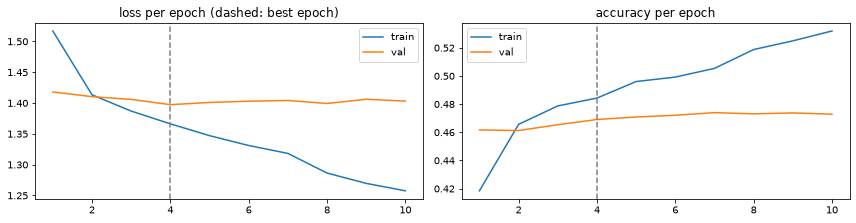

In [5]:
best_hidden = sizes_table["val accuracy"].idxmax()
network, history = runs[best_hidden]
print("keeping the network with", best_hidden, "hidden units")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
epochs = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="val")
axes[0].axvline(history["best_epoch"], color="grey", linestyle="--")
axes[0].set_title("loss per epoch (dashed: best epoch)")
axes[0].legend()
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="val")
axes[1].axvline(history["best_epoch"], color="grey", linestyle="--")
axes[1].set_title("accuracy per epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

**Finding:** the hidden layer does not help. All three sizes land at 47% on validation, the same as the linear probe.
The bigger the network, the sooner it starts to memorize: with 1,024 hidden units the best epoch is the very first one,
and after that the training loss keeps falling while the validation loss rises.

(The training accuracy shown is measured with dropout switched on, so it reads a little lower than the model's real
accuracy on the training cards.)

**Decision:** the three sizes are within 0.2 points of each other; we keep the one with the best validation accuracy
(256 hidden units) for the test below.

## 4. Test results for color

In [6]:
test_cards = cards[is_test]
probabilities = predict_probabilities(network, x[is_test])
network_result = score(test_cards.color, probabilities, COLOR_CLASSES)

results = pd.DataFrame([
    {"model": "always Multicolor", "accuracy": 0.202, "macro-F1": 0.048},
    {"model": "color histogram (03)", "accuracy": 0.340, "macro-F1": 0.304, "top-2": 0.542},
    {"model": "CLIP zero-shot, discovered words (04)", "accuracy": 0.362, "macro-F1": 0.335, "top-2": 0.535},
    {"model": "CLIP linear probe (05)", "accuracy": 0.446, "macro-F1": 0.442, "top-2": 0.675},
    {"model": "CLIP small network", **network_result},
]).set_index("model")
results.round(3)

,accuracy,macro-F1,top-2
model,,,
always Multicolor,0.202,0.048,NaN
color histogram (03),0.340,0.304,0.542
"CLIP zero-shot, discovered words (04)",0.362,0.335,0.535
CLIP linear probe (05),0.446,0.442,0.675
CLIP small network,0.448,0.439,0.668


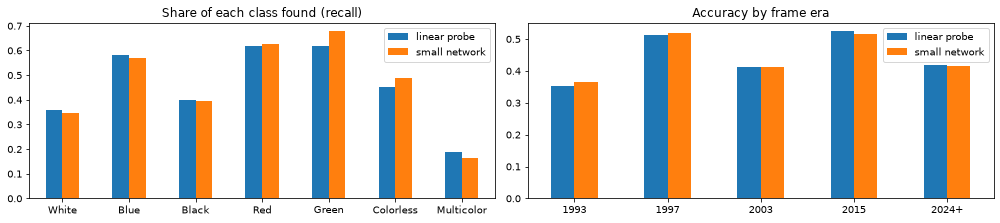

               White  Blue  Black   Red  Green  Colorless  Multicolor
linear probe    0.36  0.58   0.40  0.62   0.62       0.45        0.19
small network   0.35  0.57   0.39  0.63   0.68       0.49        0.16

                1993   1997   2003   2015  2024+
linear probe   0.352  0.511  0.411  0.524  0.419
small network  0.366  0.520  0.413  0.515  0.414


In [7]:
predicted = np.array(COLOR_CLASSES)[probabilities.argmax(axis=1)]
matrix = confusion_matrix(test_cards.color, predicted, labels=COLOR_CLASSES, normalize="true")
names = [COLOR_NAMES[c] for c in COLOR_CLASSES]

recall = pd.DataFrame({"linear probe": [0.36, 0.58, 0.40, 0.62, 0.62, 0.45, 0.19],     # from notebook 05
                       "small network": matrix.diagonal()}, index=names)

era_names = ["1993", "1997", "2003", "2015", "2024+"]
network_by_era = []
for era in era_names:
    in_era = (test_cards.era == era).to_numpy()
    network_by_era.append(score(test_cards.color[in_era], probabilities[in_era], COLOR_CLASSES)["accuracy"])
by_era = pd.DataFrame({"linear probe": [0.352, 0.511, 0.411, 0.524, 0.419],             # from notebook 05
                       "small network": network_by_era}, index=era_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
recall.plot.bar(ax=axes[0], rot=0, title="Share of each class found (recall)")
by_era.plot.bar(ax=axes[1], rot=0, title="Accuracy by frame era")
plt.tight_layout()
plt.show()
print(recall.round(2).T.to_string())
print()
print(by_era.round(3).T.to_string())

**Finding:** on the test sets the small network scores the same as the linear probe: 44.8% against 44.6% accuracy,
macro-F1 0.439 against 0.442. Per class and per era the two are within a few points of each other in both directions,
which is noise, not improvement.

So a bigger head on the same frozen features gains nothing for color. What the 512 CLIP numbers say about color,
a single layer already reads out.

## 5. Type

The same network, trained on the 7 types (same hidden size).

In [8]:
type_train_loader, type_val_loader = make_loaders(cards.type, TYPE_CLASSES)
type_network, type_history = train_network(type_train_loader, type_val_loader, best_hidden, TYPE_CLASSES, verbose=False)
type_probabilities = predict_probabilities(type_network, x[is_test])
type_result = score(test_cards.type, type_probabilities, TYPE_CLASSES)

type_results = pd.DataFrame([
    {"model": "always Creature", "accuracy": 0.499, "macro-F1": 0.095},
    {"model": "CLIP linear probe (05)", "accuracy": 0.578, "macro-F1": 0.396, "top-2": 0.742},
    {"model": "CLIP small network", **type_result},
]).set_index("model")
print("best epoch:", type_history["best_epoch"])

type_predicted = np.array(TYPE_CLASSES)[type_probabilities.argmax(axis=1)]
type_recall = pd.DataFrame({"linear probe": [0.91, 0.21, 0.68, 0.35, 0.14, 0.16, 0.14],    # from notebook 05
                            "small network": confusion_matrix(test_cards.type, type_predicted, labels=TYPE_CLASSES,
                                                              normalize="true").diagonal()}, index=TYPE_CLASSES)
print(type_recall.round(2).T.to_string())
type_results.round(3)

best epoch: 9
               Creature  Planeswalker  Land  Artifact  Enchantment  Instant  Sorcery
linear probe       0.91          0.21  0.68      0.35         0.14     0.16     0.14
small network      0.91          0.28  0.72      0.37         0.13     0.20     0.15


,accuracy,macro-F1,top-2
model,,,
always Creature,0.499,0.095,NaN
CLIP linear probe (05),0.578,0.396,0.742
CLIP small network,0.585,0.421,0.739


**Finding:** nearly the same for type: 58.5% accuracy against 57.8%, and macro-F1 0.421 against 0.396.
The small gain in macro-F1 comes from the rare types (planeswalkers 28% found instead of 21%, instants 20% instead
of 16%). It is the only place the hidden layer shows any effect, and it is modest.

## 6. Summary

| Test set | Color accuracy | Color macro-F1 | Type accuracy | Type macro-F1 |
|---|---|---|---|---|
| CLIP linear probe (05), 3,591 weights | 44.6% | 0.442 | 57.8% | 0.396 |
| CLIP small network, 133,127 weights | 44.8% | 0.439 | 58.5% | 0.421 |

- A hidden layer on top of frozen CLIP features does **not** beat the linear probe for color, and helps type only
  slightly.
- Larger networks only memorize sooner.
- **The frozen features are used up.** The limit is not the classifier on top; it is what CLIP, as trained on web
  pictures and captions, puts into its 512 numbers.

That answers the question from the start of this notebook, and it points to the next step: to get further, CLIP's own
weights have to learn from the cards.

**Next:** 05c fine-tunes CLIP itself on a GPU.
